# Spike trains: storage, encoding, and plotting

Spiking models produce rasters: boolean arrays of shape `(n_time, n_neurons)` that are mostly zeros. `braintools.spike` provides three tools for working with them:

- the `SpikeTrains` container, which stores only the spike times in a fixed-shape layout that works under `jax.jit` and `jax.vmap`;
- the **encoders**, which turn numbers or stimuli into spike rasters;
- the **bitwise operations**, which combine spike tensors and stay differentiable for surrogate-gradient spikes.

This tutorial covers the dense and event forms of a `SpikeTrains` and the conversions between them, units, the capacity `K` and how overflow is reported, the encoders, and the bitwise operations. It ends by plotting a raster, an ISI histogram and a PSTH with `braintools.visualize`, and by computing a few statistics with `braintools.analysis.spike`.

In [1]:
import brainstate
import brainunit as u
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools
from braintools.analysis import spike as spk
from braintools.spike import SpikeTrains

brainstate.environ.set(dt=0.1 * u.ms)

## 1. Dense form and event form

A **dense** raster has one row per time step and one column per neuron. Here `PoissonEncoder` draws 1 s of Poisson spikes (10,000 steps of 0.1 ms) for four neurons firing at 5, 20, 50 and 100 Hz:

In [2]:
brainstate.random.seed(0)
rates = jnp.array([5., 20., 50., 100.])  # Hz
raster = braintools.spike.PoissonEncoder()(rates, n_time=10_000)
print('raster:', raster.shape, raster.dtype, ' spikes per neuron:', raster.sum(axis=0))

raster: (10000, 4) float32  spikes per neuron: [  5.  23.  44. 104.]


The raster holds 40,000 numbers for 176 spikes. `SpikeTrains.from_dense` keeps only the spike times. Row `n` of `st.times` holds the `st.counts[n]` spike times of neuron `n` in ascending order, followed by `+inf` padding up to the **capacity** `K`, the length of the longest train. The time step comes from `brainstate.environ` (0.1 ms here), so the times are in milliseconds:

In [3]:
def in_ms(q):
    """Times as float64 milliseconds rounded to 0.1 ms, for printing."""
    return np.asarray(q.to_decimal(u.ms), dtype=np.float64).round(1)


st = SpikeTrains.from_dense(raster)
print(st)
print('counts:', st.counts, ' capacity K =', st.capacity)
print('first spike times:\n', in_ms(st.times[:, :4]), 'ms')
print('padding of neuron 0:', st.times[0, 5:8])
print('mask (valid entries):', st.mask.shape, int(st.mask.sum()), 'valid of', st.mask.size)

SpikeTrains(n_neurons=4, capacity=104, n_spikes=176, t_start=0. ms, t_stop=1000. ms, overflow=False)
counts: [  5  23  44 104]  capacity K = 104
first spike times:
 [[351.1 495.2 754.5 895.4]
 [  9.9  26.8  35.4  50.4]
 [ 16.2  75.2  88.4  99.5]
 [ 13.   54.5  66.9  67.4]] ms
padding of neuron 0: [inf inf inf] ms
mask (valid entries): (4, 104) 176 valid of 416


Every field has a static shape: `times` is `(N, K)`, `counts` is `(N,)`, and `t_start`, `t_stop` and `overflow` are scalars. That makes a `SpikeTrains` a JAX pytree that can be passed through `jit` and `vmap` (section 4).

The **event** form is a flat, time-sorted list of `(time, neuron)` pairs, as recorded by most simulators and acquisition systems. `to_events` returns it, and `from_events` builds a `SpikeTrains` from it. The events may come in any order; they are sorted per neuron. A ragged list with one array per neuron is a third form, handled by `to_list` and `from_list`.

In [4]:
times, ids = st.to_events()
print('events:', times.shape[0])
print('first 6 times:', in_ms(times[:6]), ' neurons:', ids[:6])

rng = np.random.default_rng(0)
perm = rng.permutation(times.shape[0])  # shuffle the events
st_ev = SpikeTrains.from_events(times[perm], ids[perm], n_neurons=4,
                                t_start=0. * u.ms, t_stop=1000. * u.ms)
print('same times after the shuffle:', bool(jnp.all(st_ev.times == st.times)))

trains = st.to_list()
print('ragged lengths:', [len(t) for t in trains])
print('from_list round trip:', bool(jnp.all(SpikeTrains.from_list(trains, t_start=0. * u.ms,
                                                                    t_stop=1000. * u.ms).times == st.times)))

events: 176
first 6 times: [ 9.9 13.  16.2 26.8 35.4 50.4]  neurons: [1 3 2 1 1 1]


same times after the shuffle: True
ragged lengths: [5, 23, 44, 104]
from_list round trip: True


The bounds matter: without `t_start` and `t_stop`, `from_events` and `from_list` use the first and last spike, which would shorten the recording and bias every rate computed from it.

`to_dense` goes back to a boolean raster (one row per `dt`), and the round trip is exact:

In [5]:
dense = st.to_dense()
print(dense.shape, dense.dtype, ' equal to the raster:', bool((dense == (raster != 0)).all()))

(10000, 4) bool  equal to the raster: True


## 2. Binning, windows and selections

`bin(bin_size)` counts spikes in consecutive bins starting at `t_start`, giving an `(n_bins, N)` array. Dividing the mean count by the bin width gives the firing rate. `window(t0, t1)` keeps the spikes in `[t0, t1)` (with the same capacity), and `select(idx)` keeps a subset of neurons.

In [6]:
counts = st.bin(100 * u.ms)
print('binned:', counts.shape)
print(counts[:3])
print('rate (Hz):', counts.mean(axis=0) / 0.1)

w = st.window(200 * u.ms, 500 * u.ms)
print(w)
print('counts in [200, 500) ms:', w.counts)
print(st.select([3, 1]))

binned: (10, 4)
[[ 0  4  4  8]
 [ 0  1  5 13]
 [ 0  2  7 10]]
rate (Hz): [  5.       23.       44.      104.00001]


SpikeTrains(n_neurons=4, capacity=104, n_spikes=56, t_start=200. ms, t_stop=500. ms, overflow=False)
counts in [200, 500) ms: [ 2  7 15 32]
SpikeTrains(n_neurons=2, capacity=104, n_spikes=127, t_start=0. ms, t_stop=1000. ms, overflow=False)


The rates are the spike counts per second, 5, 23, 44 and 104 Hz, close to the requested 5, 20, 50 and 100 Hz for a 1 s sample.

## 3. Units, `dt` and `t0`

When `dt` is a `brainunit` Quantity (the default from `brainstate.environ` is one here), `times`, `t_start` and `t_stop` are Quantities in that unit, and every time argument (`bin_size`, window bounds, ...) must be a Quantity with time dimensions. Any time unit works: `bin(0.1 * u.second)` gives the same bins as `bin(100 * u.ms)`. `t_start` shifts the time of row 0. With a plain `dt`, the times are plain numbers.

In [7]:
st_shift = SpikeTrains.from_dense(raster, dt=0.1 * u.ms, t_start=500 * u.ms)
print('t_start, t_stop:', st_shift.t_start, st_shift.t_stop)
print('first spikes of neuron 1 :', in_ms(st.times[1, :3]), '->',
      in_ms(st_shift.times[1, :3]), 'ms')
print('bins in seconds = bins in ms:', bool((st.bin(0.1 * u.second) == counts).all()))

st_plain = SpikeTrains.from_dense(raster, dt=0.1)
print('unitless times:', np.asarray(st_plain.times[1, :3], dtype=np.float64).round(1), ' t_stop =', st_plain.t_stop)

t_start, t_stop: 500. ms 1500. ms
first spikes of neuron 1 : [ 9.9 26.8 35.4] -> [509.9 526.8 535.4] ms


bins in seconds = bins in ms: True
unitless times: [ 9.9 26.8 35.4]  t_stop = 1000.0


Mixing the two is an error, so a missing unit is caught instead of silently read as milliseconds:

In [8]:
try:
    SpikeTrains.from_dense(raster, dt=0.1 * u.ms, t_start=5.)
except TypeError as e:
    print('TypeError:', e)
try:
    st.bin(1 * u.mV)
except u.UnitMismatchError as e:
    print('UnitMismatchError:', e)

TypeError: `t_start` must be a Quantity compatible with ms because `dt` is a Quantity; got the plain value 5.0.
UnitMismatchError: Cannot convert to the decimal number using a unit with different dimensions. (units are mV and ms).


## 4. Capacity and overflow

The capacity `K` is part of the array shapes, so it must be fixed when a function is traced:

- With concrete input and `capacity=None`, `K` is the largest spike count (104 above).
- With concrete input, a capacity that is too small raises `ValueError` right away.
- Inside `jit` or `vmap`, the counts are not known at trace time, so `capacity` must be given. If a neuron fires more often, its first `K` spikes are kept, its count is clipped to `K`, and the `overflow` flag is set. The function cannot raise inside the transform; call `check()` on the result afterwards to turn the flag into an error.

In [9]:
try:
    SpikeTrains.from_dense(raster, capacity=50)
except ValueError as e:
    print('ValueError:', e)

to_trains = jax.jit(lambda r: SpikeTrains.from_dense(r, dt=0.1 * u.ms, capacity=64))
st_j = to_trains(raster)
print(st_j)
print('counts:', st_j.counts, ' overflow:', bool(st_j.overflow))
try:
    st_j.check()
except ValueError as e:
    print('ValueError:', e)

ValueError: SpikeTrains.from_dense: neuron 3 has 104 spikes, more than capacity=50. Increase `capacity`, or pass `capacity=None` to size it from the data.


SpikeTrains(n_neurons=4, capacity=64, n_spikes=136, t_start=0. ms, t_stop=1000. ms, overflow=True)
counts: [ 5 23 44 64]  overflow: True
ValueError: SpikeTrains overflow: some neuron had more than capacity=64 spikes, and the extra spikes were dropped. Rebuild with a larger `capacity`.


Neuron 3 had 104 spikes, so with `K = 64` it lost 40 of them and `overflow` is `True`. A safe capacity is an upper bound on the count: the number of time steps always works, and for a known rate a bound a few standard deviations above the expected count is enough.

`jax.vmap` builds one `SpikeTrains` per trial with a shared capacity. Below are 20 trials of the same four neurons. With `K = 110`, a trial overflows whenever the 100 Hz neuron fires more than 110 spikes, and `overflow` (one flag per trial) shows which trials did. With `K = 160` none do:

In [10]:
brainstate.random.seed(1)
trials = braintools.spike.PoissonEncoder()(jnp.tile(rates, (20, 1)), n_time=10_000)  # (T, 20, 4)
trials = jnp.moveaxis(trials, 1, 0)                                                 # (20, T, 4)
print('trials:', trials.shape)

for K in (110, 160):
    batched = jax.vmap(lambda r: SpikeTrains.from_dense(r, dt=0.1 * u.ms, capacity=K))(trials)
    print(f'K={K}: times {batched.times.shape}, trials with overflow: '
          f'{np.flatnonzero(np.asarray(batched.overflow)).tolist()}')
print('true counts of the 100 Hz neuron:', np.asarray(trials[:, :, 3].sum(axis=1), dtype=int).tolist())
print('mean count per neuron:', np.asarray(batched.counts.mean(axis=0)))

trials: (20, 10000, 4)


K=110: times (20, 4, 110), trials with overflow: [16]


K=160: times (20, 4, 160), trials with overflow: []
true counts of the 100 Hz neuron: [93, 95, 106, 88, 107, 94, 106, 104, 102, 75, 94, 92, 85, 102, 87, 100, 112, 94, 101, 107]
mean count per neuron: [ 4.       20.75     46.8      97.200005]


## 5. Encoders: from stimuli to spikes

The encoders in `braintools.spike` turn numbers or time series into spike rasters with time on axis 0, which go straight into `SpikeTrains.from_dense` (`StepCurrentEncoder` is the exception: it returns an input current for a neuron model):

| Encoder | Code |
|---|---|
| `RateEncoder`, `PoissonEncoder`, `BernoulliEncoder` | the value sets a firing rate or a spike probability per step |
| `PopulationEncoder` | a population with Gaussian tuning curves; the bump of activity marks the value |
| `LatencyEncoder`, `RankOrderEncoder` | one spike per feature; larger values fire earlier |
| `SpikeCountEncoder` | a fixed number of spikes that grows with the value |
| `DeltaEncoder`, `StepCurrentEncoder` | changes of a signal; a current that drives a neuron model |
| `TemporalEncoder` | a fixed random spike pattern per symbol |

Below, eight values evenly spaced in `[0, 1]` are encoded for 200 ms by four of them. The population code encodes the single value 0.3 with 16 neurons whose preferred values tile `[0, 1]`.

RateEncoder (rate = 100 Hz * x)      raster (2000, 8)  counts [0, 6, 6, 9, 12, 11, 11, 23]


PoissonEncoder (normalize, 100 Hz)   raster (2000, 8)  counts [0, 3, 3, 14, 7, 16, 22, 9]


LatencyEncoder (linear)              raster (2000, 8)  counts [1, 1, 1, 1, 1, 1, 1, 1]


PopulationEncoder (value 0.3)        raster (2000, 16)  counts [2, 3, 13, 23, 35, 34, 26, 17, 3, 0, 0, 0, 0, 0, 0, 0]


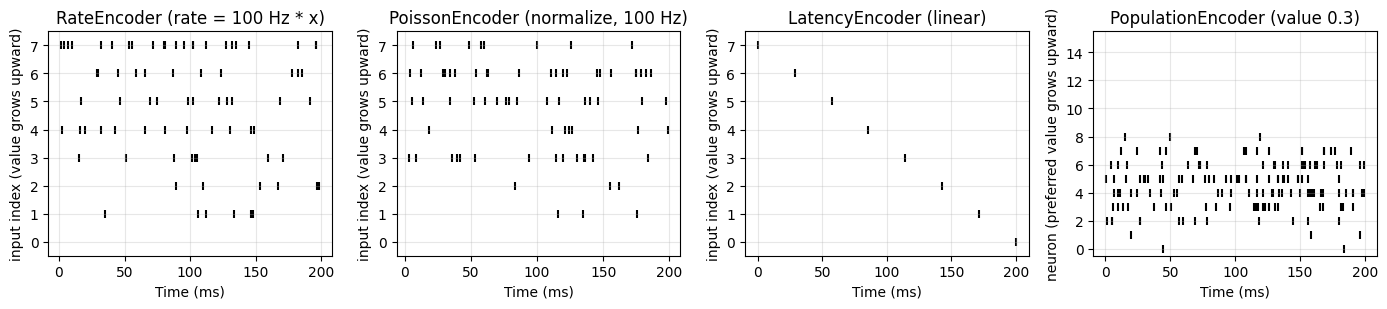

In [11]:
brainstate.random.seed(2)
x = jnp.linspace(0., 1., 8)
encoded = {
    'RateEncoder (rate = 100 Hz * x)': braintools.spike.RateEncoder(gain=100.)(x, n_time=2000),
    'PoissonEncoder (normalize, 100 Hz)': braintools.spike.PoissonEncoder(normalize=True, max_rate=100.)(x, n_time=2000),
    'LatencyEncoder (linear)': braintools.spike.LatencyEncoder(method='linear', normalize=True)(x, n_time=2000),
    'PopulationEncoder (value 0.3)': braintools.spike.PopulationEncoder(n_neurons=16, sigma=0.1, max_rate=200.)(0.3, n_time=2000),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (name, r) in zip(axes, encoded.items()):
    trains_e = SpikeTrains.from_dense(r)
    print(f'{name:36s} raster {tuple(r.shape)}  counts {np.asarray(trains_e.counts).tolist()}')
    braintools.visualize.spike_raster(trains_e, ax=ax, markersize=30, title=name)
    ax.set_ylim(-0.5, r.shape[1] - 0.5)
for ax in axes[:3]:
    ax.set_ylabel('input index (value grows upward)')
axes[3].set_ylabel('neuron (preferred value grows upward)')
plt.tight_layout()
plt.show()

The rate codes fire more often for larger values (input 0, at value 0, stays silent); the latency code fires once per input, earlier for larger values (input 7, at value 1, fires at 0 ms); and the population code peaks at neurons 4 and 5, whose preferred values 0.27 and 0.33 surround 0.3. The {doc}`spike-encoding tutorial <../misc/spike_encoding>` covers all ten encoders and checks each against the rates, timings or counts it should produce.

## 6. Bitwise spike operations

`bitwise_or`, `bitwise_and`, `bitwise_xor`, `bitwise_not`, `bitwise_iand` (`(NOT x) AND y`) and `bitwise_ixor` combine spike tensors element-wise, and `bitwise(x, y, op)` dispatches by name. For 0/1 values they compute the logical operations through arithmetic identities, for example `x OR y = x + y - x y`. Here two independent 50 Hz Poisson rasters of 100 neurons over 100 ms are combined, and the counts obey the identities `|A OR B| = |A| + |B| - |A AND B|` and `|A XOR B| = |A OR B| - |A AND B|`:

In [12]:
brainstate.random.seed(3)
A = braintools.spike.PoissonEncoder()(jnp.full(100, 50.), n_time=1000)
B = braintools.spike.PoissonEncoder()(jnp.full(100, 50.), n_time=1000)
n_a, n_b = int(A.sum()), int(B.sum())
n_or = int(braintools.spike.bitwise_or(A, B).sum())
n_and = int(braintools.spike.bitwise_and(A, B).sum())
n_xor = int(braintools.spike.bitwise_xor(A, B).sum())
print(f'|A| = {n_a}, |B| = {n_b}, |A OR B| = {n_or}, |A AND B| = {n_and}, |A XOR B| = {n_xor}')
print('OR identity :', n_or == n_a + n_b - n_and, ' XOR identity:', n_xor == n_or - n_and)
print('NOT A       :', int(braintools.spike.bitwise_not(A).sum()), '=', A.size, '-', n_a)
print("bitwise(A, B, 'iand') equals (NOT A) AND B:",
      bool((braintools.spike.bitwise(A, B, 'iand') == braintools.spike.bitwise_and(1 - A, B)).all()))

|A| = 510, |B| = 533, |A OR B| = 1041, |A AND B| = 2, |A XOR B| = 1039
OR identity : True  XOR identity: True
NOT A       : 99490 = 100000 - 510
bitwise(A, B, 'iand') equals (NOT A) AND B: True


Coincidences are rare: with a spike probability of about 0.005 per step and neuron, only a handful of the 100,000 entries are 1 in both rasters.

With boolean inputs the operations use the logical functions and return a boolean mask. With floating-point inputs, such as the spikes of a surrogate-gradient neuron, the identities are differentiable: the gradient of `x OR y` with respect to `x` is `1 - y`.

In [13]:
print('bool in -> ', braintools.spike.bitwise_or(A > 0, B > 0).dtype)
x_s = jnp.array([0., 1., 0., 1.])
y_s = jnp.array([0., 0., 1., 1.])
grad_x = jax.grad(lambda a: braintools.spike.bitwise_or(a, y_s).sum())(x_s)
print('d(x OR y)/dx =', grad_x, ' 1 - y =', 1 - y_s)

bool in ->  bool


d(x OR y)/dx = [1. 1. 0. 0.]  1 - y = [1. 1. 0. 0.]


## 7. Plotting a `SpikeTrains`

The spike plots of `braintools.visualize` accept a `SpikeTrains` directly and label the time axis with its unit. To get data with structure, we simulate 40 noisy leaky integrate-and-fire (LIF) neurons for 2 s. Each neuron gets a constant drive near threshold plus white noise, and a stimulus raises the drive during [500, 700) ms and [1300, 1500) ms. After a spike the membrane is held at reset for a 2 ms refractory period.

The 20,000 time steps run in one compiled `brainstate.transform.for_loop`. The membrane potential and the refractory timer are `brainstate.State`s, which the loop carries automatically, and the stacked spikes form the raster.

In [14]:
N, T = 40, 20_000                      # neurons, steps of 0.1 ms (2 s)
dt, tau = 0.1, 20.                     # ms
v_th, v_reset, t_ref, sigma = 1., 0., 2., 0.25
stim_on = jnp.zeros(T).at[5000:7000].set(1.).at[13000:15000].set(1.)

brainstate.random.seed(4)
drive = brainstate.random.uniform(0.9, 1.1, N)
v = brainstate.State(jnp.zeros(N))
refractory = brainstate.State(jnp.zeros(N))


def lif_step(i):
    noise = sigma * jnp.sqrt(tau / dt) * brainstate.random.randn(N)
    I = drive + 0.6 * stim_on[i] + noise
    v_new = jnp.where(refractory.value > 0, v_reset, v.value + dt / tau * (I - v.value))
    spike = v_new >= v_th
    v.value = jnp.where(spike, v_reset, v_new)
    refractory.value = jnp.where(spike, t_ref, jnp.maximum(refractory.value - dt, 0.))
    return spike


lif_raster = brainstate.transform.for_loop(lif_step, jnp.arange(T))
lif = SpikeTrains.from_dense(lif_raster)   # dt = 0.1 ms from brainstate.environ
print(lif)
print(f'mean rate: {float(lif.counts.mean()) / 2.0:.1f} Hz')

SpikeTrains(n_neurons=40, capacity=61, n_spikes=1991, t_start=0. ms, t_stop=2000. ms, overflow=False)
mean rate: 24.9 Hz


For comparison, a Poisson population with the same mean rate has no refractory period and no memory:

In [15]:
brainstate.random.seed(5)
mean_rate = float(lif.counts.mean()) / 2.0
pois = SpikeTrains.from_dense(braintools.spike.PoissonEncoder()(jnp.full(N, mean_rate), n_time=T))
print(pois)

SpikeTrains(n_neurons=40, capacity=65, n_spikes=2031, t_start=0. ms, t_stop=2000. ms, overflow=False)


`spike_raster` draws the raster, `spike_histogram` the population PSTH (all neurons pooled, here in 20 ms bins), and `isi_distribution` the histogram of inter-spike intervals within each neuron, with their mean and CV in the box.

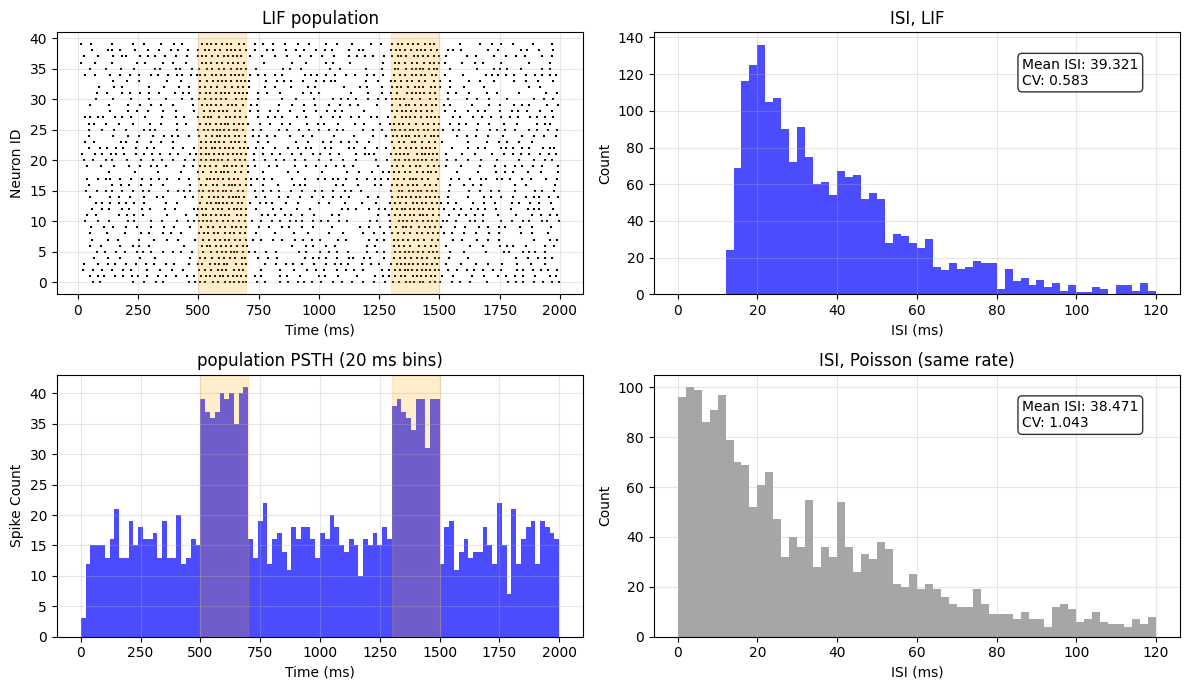

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
braintools.visualize.spike_raster(lif, ax=axes[0, 0], markersize=4, title='LIF population')
braintools.visualize.spike_histogram(lif, bin_size=20 * u.ms, time_range=(0 * u.ms, 2000 * u.ms),
                                     ax=axes[1, 0], title='population PSTH (20 ms bins)')
for ax in axes[:, 0]:
    for t_on in (500, 1300):
        ax.axvspan(t_on, t_on + 200, color='orange', alpha=0.2)
isi_bins = np.arange(0, 122, 2)  # ms; the histogram shows intervals up to 120 ms
braintools.visualize.isi_distribution(lif, bins=isi_bins, ax=axes[0, 1], xlabel='ISI (ms)',
                                      title='ISI, LIF')
braintools.visualize.isi_distribution(pois, bins=isi_bins, ax=axes[1, 1], color='gray',
                                      xlabel='ISI (ms)', title='ISI, Poisson (same rate)')
plt.tight_layout()
plt.show()

The raster and the PSTH show the population rate rising during the two stimuli (shaded). The two ISI histograms differ in shape. After a spike, an LIF neuron must charge from reset back to threshold, so intervals shorter than about 12 ms do not occur and the histogram peaks near 20 ms. The Poisson intervals are exponential, with the most intervals in the first bins. The box reports the mean and the CV of all intervals pooled over neurons; the bins only limit what is drawn.

## 8. Spike statistics with `braintools.analysis.spike`

The statistics in `braintools.analysis.spike` take a `SpikeTrains` too and return one value per neuron. They are JAX functions, so they work under `jit` and `vmap`. Three common ones:

- `cv(trains)`: the coefficient of variation of the inter-spike intervals (1 for a Poisson process, 0 for a clock);
- `fano_factor(trains, bin_size)`: the variance-to-mean ratio of the spike counts in bins (1 for a Poisson process);
- `psth(trains, events, window, bin_size)`: the event-aligned peri-stimulus time histogram, averaged over the events, in Hz.

CV          LIF 0.55   Poisson 1.02


Fano (100 ms) LIF 0.70   Poisson 1.01


psth: (35, 40)  edges -200. ms ... 500. ms


population rate before onset: 18.9 Hz, during the stimulus: 47.2 Hz


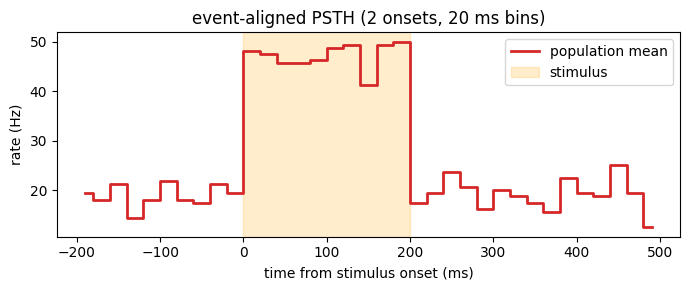

In [17]:
print(f'CV          LIF {float(jnp.nanmean(spk.cv(lif))):.2f}   Poisson {float(jnp.nanmean(spk.cv(pois))):.2f}')
print(f'Fano (100 ms) LIF {float(jnp.nanmean(spk.fano_factor(lif, 100 * u.ms))):.2f}   '
      f'Poisson {float(jnp.nanmean(spk.fano_factor(pois, 100 * u.ms))):.2f}')

onsets = jnp.array([500., 1300.]) * u.ms
rate, edges = spk.psth(lif, onsets, window=(200 * u.ms, 500 * u.ms), bin_size=20 * u.ms)
print('psth:', rate.shape, ' edges', edges[0], '...', edges[-1])
centers = ((edges[:-1] + edges[1:]) / 2).to_decimal(u.ms)
pop_rate = np.asarray(rate.mean(axis=1))
print(f'population rate before onset: {pop_rate[centers < 0].mean():.1f} Hz, '
      f'during the stimulus: {pop_rate[(centers > 0) & (centers < 200)].mean():.1f} Hz')

plt.figure(figsize=(7, 3))
plt.step(centers, pop_rate, where='mid', color='C3', lw=2, label='population mean')
plt.axvspan(0, 200, color='orange', alpha=0.2, label='stimulus')
plt.xlabel('time from stimulus onset (ms)')
plt.ylabel('rate (Hz)')
plt.title('event-aligned PSTH (2 onsets, 20 ms bins)')
plt.legend()
plt.tight_layout()
plt.show()

The LIF neurons fire more regularly than a Poisson process: their mean CV (0.55) and Fano factor (0.70) are below 1, while the Poisson population is close to 1 for both. The PSTH aligns the spikes to the two stimulus onsets and averages over them: the population rate jumps from about 19 Hz to about 47 Hz at onset and falls back when the stimulus ends at 200 ms.

The CV printed here is the mean of the per-neuron CVs, while the box of `isi_distribution` pools the intervals of all neurons first. Pooling mixes neurons with different mean rates, which widens the distribution, so the pooled CV is a little larger.

For the rest of the toolbox (correlograms, spike-train distances, synchrony, spike-triggered averages) see the {doc}`analysis tutorials <../analysis/index>`, and for the full list of spike functions the {doc}`API reference <../apis/spike>`.